# 实验1：安装与验证 OpenCV

本实验的图片、代码和操作步骤均已包含在本文件夹中。

**运行方式：** 选择本项目的 `.venv` 内核，依次执行单元格，或点击“全部运行”。重新开始时先重启内核。

## 实验目的

建立独立 Python 环境，理解 pip 包名和导入名的区别，验证 OpenCV 可用。

## 实验原理

本实验使用 Python 安装包：安装名为 `opencv-python-headless`，导入名为 `cv2`。无窗口版本足够完成全部 Notebook 实验；同一个环境只保留一种 OpenCV Python 发行包。


## 1. 准备环境与路径

算法使用 OpenCV；显示使用 Matplotlib。彩色数组按 BGR 存储，显示前转换成 RGB。图中标题采用英文，说明和练习采用中文，减少系统字体差异。


In [1]:
from pathlib import Path
import sys

# 从 lab 根目录或任意实验子目录启动均可。
HERE = Path.cwd().resolve()
ROOT = next((p for p in (HERE, *HERE.parents)
             if (p / "assets" / "manifest.json").is_file()
             and (p / "common" / "io.py").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("请在 lab 文件夹或其子目录中启动 Notebook。")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import cv2
import numpy as np
import matplotlib.pyplot as plt
from common.io import read_image, save_image, show_images

ASSETS = ROOT / "assets"
OUT = ROOT / "outputs" / "lab01"
OUT.mkdir(parents=True, exist_ok=True)


Matplotlib is building the font cache; this may take a moment.


## 2. 查看环境

先按根目录 README 创建环境并安装依赖，再运行这里。若导入失败，请核对右上角内核是否来自 `.venv`。


In [2]:
import platform
print("Python:", platform.python_version())
print("Interpreter:", sys.executable)
print("OpenCV:", cv2.__version__)
print("NumPy:", np.__version__)
print("Project:", ROOT.name)


Python: 3.12.14
Interpreter: /private/tmp/opencv_lab_verify/bin/python
OpenCV: 4.14.0
NumPy: 2.5.4
Project: lab


## 3. 验证图像计算

创建蓝、绿、红三条色带，再转换到灰度。注意 BGR 中蓝色对应第 0 通道。


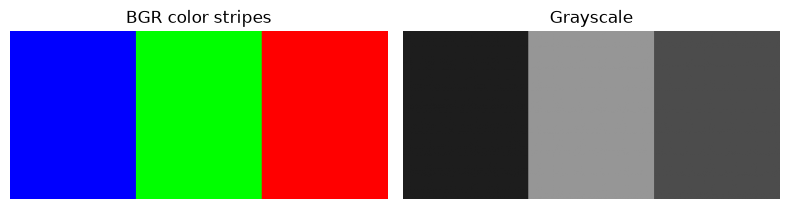

OpenCV 图像计算正常。


In [3]:
stripes = np.zeros((160, 360, 3), dtype=np.uint8)
stripes[:, :120] = (255, 0, 0)
stripes[:, 120:240] = (0, 255, 0)
stripes[:, 240:] = (0, 0, 255)
gray = cv2.cvtColor(stripes, cv2.COLOR_BGR2GRAY)
show_images({"BGR color stripes": stripes, "Grayscale": gray}, cols=2,
            save_to=OUT / "installation_check.png")
assert gray.shape == (160, 360)
print("OpenCV 图像计算正常。")


## 4. 验证本地素材

不用摄像头和网络，也能完成九个实验。


瓶盖图像 shape: (370, 370, 3) dtype: uint8


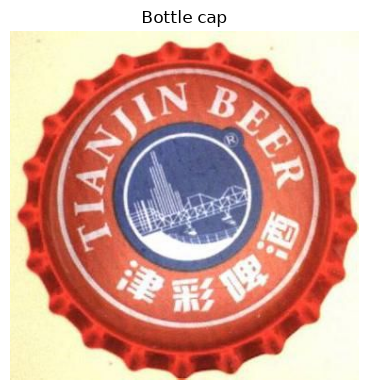

In [4]:
image = read_image(ASSETS / "pdf/bottle_cap.png")
print("瓶盖图像 shape:", image.shape, "dtype:", image.dtype)
show_images({"Bottle cap": image}, cols=1)


## 记录与思考

1. `pip` 安装成功但 `import cv2` 失败，可能是哪一个环境选错了？
2. 三条色带的灰度为何不同？
3. 找出 NumPy 数组的高度、宽度和通道数。

### 我的实验记录

- 使用的素材：
- 修改的参数：
- 观察到的现象：
- 结论与原因：

> 图像和图表保存到 `outputs/lab01/`；运行本 Notebook 不会改写原始素材。
